In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "src").is_dir(), "Project root not found."

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

LOCAL_DEPS = PROJECT_ROOT / ".python_deps"

if LOCAL_DEPS.is_dir():
    sys.path.insert(0, str(LOCAL_DEPS))

from src.agents.learned_policy import (
    STATE_DIM,
    ACTION_DIM,
    ACTION_ORDER,
)

print("Project root:", PROJECT_ROOT)
print("State dimension:", STATE_DIM)
print("Action dimension:", ACTION_DIM)
print("Actions:", [action.value for action in ACTION_ORDER])

assert STATE_DIM == 28
assert ACTION_DIM == 5

print("\nPASS: MotionProof AI Notebook 2 initialized.")

Project root: /blue/eee6778/nvasanthakumar/MotionProof-AI
State dimension: 28
Action dimension: 5
Actions: ['ACCEPT', 'FLAG_UNRELIABLE', 'CHECK_PPG', 'CHECK_MOTION', 'CHECK_CONSISTENCY']

PASS: MotionProof AI Notebook 2 initialized.


In [2]:
import sys
import traceback
import importlib.metadata as metadata

print("Python executable:", sys.executable)

for package in ["torch", "dill", "typing_extensions"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

try:
    import dill

    print("\nDill location:", dill.__file__)
    print("Dill extend available:", hasattr(dill, "extend"))

    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    print("\nPASS: PyTorch environment ready.")

except Exception as error:
    print("\n=== PYTORCH IMPORT ERROR ===")
    print("Exception:", type(error).__name__)
    print("Message:", str(error))

    print("\n=== TRACEBACK (LAST 15 LINES) ===")
    print(
        "".join(
            traceback.format_exception(
                type(error),
                error,
                error.__traceback__,
            )[-15:]
        )
    )

Python executable: /apps/jupyter/6.5.4/bin/python
torch: 2.9.1
dill: 0.3.7
typing_extensions: 4.16.0

Dill location: /blue/eee6778/nvasanthakumar/MotionProof-AI/.python_deps/dill/__init__.py
Dill extend available: True

PyTorch version: 2.9.1+cu128
CUDA available: True

PASS: PyTorch environment ready.


In [8]:
import ast
import numpy as np
import pandas as pd
import torch

from src.agents.learned_policy import (
    ACTION_ORDER,
    ACTION_DIM,
    STATE_DIM,
    STATE_FEATURE_NAMES,
)
from src.agents.policy_network import PolicyQNetwork

# ============================================================
# 0. REPRODUCIBILITY
# ============================================================

torch.manual_seed(42)
np.random.seed(42)

dataset_path = (
    PROJECT_ROOT
    / "results/metrics/policy_investigation_states.csv"
)

# Preserve empty investigation sequences.
df = pd.read_csv(
    dataset_path,
    keep_default_na=False,
)

df["sequence"] = df["sequence"].astype(str)

print("Dataset shape:", df.shape)
print("Unique subjects:", sorted(df.subject.unique()))
print("State dimensions:", STATE_DIM)

assert len(df) == 10000, "Unexpected pilot dataset size."
assert set(df.subject.unique()) == set(range(1, 11))
assert (df["sequence"] == "").sum() == 1000

print("PASS: Initial investigation sequences preserved.")

# ============================================================
# 1. CONVERT REWARD DICTIONARIES TO NUMERIC VALUES
# ============================================================

def extract_total_reward(value):
    """
    Extract the numeric total_reward from a stored reward
    dictionary or numeric value.
    """

    if isinstance(value, dict):
        return float(value["total_reward"])

    if isinstance(value, str):
        parsed = ast.literal_eval(value)

        if isinstance(parsed, dict):
            return float(parsed["total_reward"])

        return float(parsed)

    return float(value)


df["accept_reward"] = df["accept_reward"].map(
    extract_total_reward
)

df["flag_reward"] = df["flag_reward"].map(
    extract_total_reward
)

reward_values = df[
    ["accept_reward", "flag_reward"]
].to_numpy(dtype=np.float32)

assert np.isfinite(reward_values).all()

print("PASS: Reward dictionaries converted to numeric values.")

# ============================================================
# 2. BUILD STATE LOOKUP
# ============================================================

state_lookup = {}

for index, row in df.iterrows():

    key = (
        int(row["subject"]),
        int(row["window_index"]),
        str(row["sequence"]),
    )

    if key in state_lookup:
        raise ValueError(
            f"Duplicate investigation state: {key}"
        )

    state_lookup[key] = index

assert len(state_lookup) == len(df)

print("PASS: State lookup constructed.")

# ============================================================
# 3. INITIALIZE OFFLINE Q TARGETS
# ============================================================

q_targets = np.full(
    (len(df), ACTION_DIM),
    np.nan,
    dtype=np.float32,
)

action_names = [
    action.value
    for action in ACTION_ORDER
]

accept_index = action_names.index("ACCEPT")
flag_index = action_names.index("FLAG_UNRELIABLE")

q_targets[:, accept_index] = (
    df["accept_reward"].to_numpy(dtype=np.float32)
)

q_targets[:, flag_index] = (
    df["flag_reward"].to_numpy(dtype=np.float32)
)

print("PASS: Terminal action rewards initialized.")

# ============================================================
# 4. BACKWARD Q-TARGET CALCULATION
# ============================================================

investigation_actions = [
    "CHECK_PPG",
    "CHECK_MOTION",
    "CHECK_CONSISTENCY",
]

# Terminal rewards already include cumulative investigation
# penalties, so we do not subtract the costs again.

for depth in [1, 0]:

    rows_at_depth = df.index[
        df["investigations_used"] == depth
    ]

    for index in rows_at_depth:

        row = df.loc[index]

        sequence = str(row["sequence"])

        for action in investigation_actions:

            if not bool(row[f"valid_{action}"]):
                continue

            # Construct the next investigation sequence.
            next_sequence = (
                action
                if sequence == ""
                else sequence + "|" + action
            )

            next_key = (
                int(row["subject"]),
                int(row["window_index"]),
                next_sequence,
            )

            if next_key not in state_lookup:
                raise KeyError(
                    f"Missing next state: {next_key}"
                )

            next_index = state_lookup[next_key]

            next_valid = np.array(
                [
                    bool(
                        df.at[
                            next_index,
                            f"valid_{name}"
                        ]
                    )
                    for name in action_names
                ],
                dtype=bool,
            )

            assert next_valid.any(), (
                f"No valid actions in state {next_key}"
            )

            next_q_values = q_targets[
                next_index,
                next_valid
            ]

            assert np.isfinite(next_q_values).all(), (
                f"Invalid next-state Q values: {next_key}"
            )

            q_targets[
                index,
                action_names.index(action)
            ] = np.max(next_q_values)

# ============================================================
# 5. VALIDATE Q TARGETS AND ACTION MASKS
# ============================================================

valid_mask = df[
    [
        f"valid_{name}"
        for name in action_names
    ]
].to_numpy(dtype=bool)

assert valid_mask.shape == q_targets.shape

assert np.isfinite(
    q_targets[valid_mask]
).all(), "Nonfinite Q targets found."

# Invalid actions should not have targets.
assert np.isnan(
    q_targets[~valid_mask]
).all(), "Invalid actions unexpectedly have Q targets."

print("PASS: Offline Q targets generated.")
print("Q-target shape:", q_targets.shape)

# ============================================================
# 6. PREPARE POLICY STATE FEATURES
# ============================================================

X = df[
    list(STATE_FEATURE_NAMES)
].to_numpy(dtype=np.float32)

assert X.shape == (
    len(df),
    STATE_DIM,
)

assert np.isfinite(X).all()

# Fit normalization using training data only.
feature_mean = X.mean(axis=0)
feature_std = X.std(axis=0)

# Avoid division by zero for constant features.
feature_std = np.where(
    feature_std < 1e-6,
    1.0,
    feature_std,
)

X_normalized = (
    X - feature_mean
) / feature_std

assert np.isfinite(X_normalized).all()

print("PASS: State features normalized.")

# ============================================================
# 7. PREPARE PYTORCH TENSORS
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Training device:", device)

X_tensor = torch.tensor(
    X_normalized,
    dtype=torch.float32,
    device=device,
)

targets_tensor = torch.tensor(
    np.nan_to_num(
        q_targets,
        nan=0.0,
    ),
    dtype=torch.float32,
    device=device,
)

mask_tensor = torch.tensor(
    valid_mask,
    dtype=torch.bool,
    device=device,
)

print("PASS: PyTorch training tensors prepared.")

# ============================================================
# 8. INITIALIZE POLICY Q-NETWORK
# ============================================================

network = PolicyQNetwork(
    hidden_dim=64
).to(device)

optimizer = torch.optim.Adam(
    network.parameters(),
    lr=1e-3,
)

loss_function = torch.nn.SmoothL1Loss()

parameter_count = sum(
    parameter.numel()
    for parameter in network.parameters()
)

print("Network parameters:", parameter_count)

# ============================================================
# 9. TRAIN NEURAL POLICY
# ============================================================

history = []

epochs = 40
batch_size = 512

print("\nStarting pilot policy training...\n")

for epoch in range(epochs):

    network.train()

    permutation = torch.randperm(
        len(X_tensor),
        device=device,
    )

    epoch_losses = []

    for start in range(
        0,
        len(X_tensor),
        batch_size,
    ):

        indices = permutation[
            start:start + batch_size
        ]

        predictions = network(
            X_tensor[indices]
        )

        batch_mask = mask_tensor[indices]

        predicted_q = predictions[
            batch_mask
        ]

        target_q = targets_tensor[
            indices
        ][batch_mask]

        loss = loss_function(
            predicted_q,
            target_q,
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        epoch_losses.append(
            float(loss.item())
        )

    mean_loss = float(
        np.mean(epoch_losses)
    )

    history.append(
        {
            "epoch": epoch + 1,
            "loss": mean_loss,
        }
    )

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch {epoch + 1:02d}/{epochs}"
            f" | Loss: {mean_loss:.6f}"
        )

print("\nPASS: Neural policy training completed.")

# ============================================================
# 10. SAVE MODEL CHECKPOINT
# ============================================================

checkpoint_path = (
    PROJECT_ROOT
    / "checkpoints/learned_policy_pilot.pt"
)

checkpoint_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

network = network.cpu()
network.eval()

torch.save(
    {
        "model_state_dict": network.state_dict(),

        "feature_mean": feature_mean,

        "feature_std": feature_std,

        "state_feature_names": tuple(
            STATE_FEATURE_NAMES
        ),

        "action_names": action_names,

        "state_dim": STATE_DIM,

        "action_dim": ACTION_DIM,

        "hidden_dim": 64,

        "training_subjects": list(
            range(1, 11)
        ),

        "pilot_windows_per_subject": 100,

        "training_method": (
            "offline_oracle_finite_horizon_q_targets"
        ),

        "epochs": epochs,

        "final_training_loss": history[-1]["loss"],
    },
    checkpoint_path,
)

print("PASS: Model checkpoint saved.")

# ============================================================
# 11. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history
)

history_path = (
    PROJECT_ROOT
    / "results/metrics/learned_policy_pilot_training.csv"
)

history_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

history_df.to_csv(
    history_path,
    index=False,
)

print("PASS: Training history saved.")

# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("MOTIONPROOF AI — PILOT POLICY TRAINING")
print("=" * 60)

print("Training windows:", 1000)
print("Investigation states:", len(df))
print("State dimensions:", STATE_DIM)
print("Action dimensions:", ACTION_DIM)
print("Network parameters:", parameter_count)
print("Training device:", device)
print("Epochs:", epochs)
print("Final training loss:", history_df.loss.iloc[-1])

print("\nCheckpoint:")
print(checkpoint_path)

print("\nTraining history:")
print(history_path)

print("\nPASS: Pilot learned policy trained.")
print("=" * 60)

Dataset shape: (10000, 40)
Unique subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
State dimensions: 28
PASS: Initial investigation sequences preserved.
PASS: Reward dictionaries converted to numeric values.
PASS: State lookup constructed.
PASS: Terminal action rewards initialized.
PASS: Offline Q targets generated.
Q-target shape: (10000, 5)
PASS: State features normalized.
Training device: cuda
PASS: PyTorch training tensors prepared.
Network parameters: 6341

Starting pilot policy training...

Epoch 05/40 | Loss: 0.372247
Epoch 10/40 | Loss: 0.338145
Epoch 15/40 | Loss: 0.310053
Epoch 20/40 | Loss: 0.287234
Epoch 25/40 | Loss: 0.275327
Epoch 30/40 | Loss: 0.269272
Epoch 35/40 | Loss: 0.264255
Epoch 40/40 | Loss: 0.260242

PASS: Neural policy training completed.
PASS: Model checkpoint saved.
PASS: Training history saved.

MOTIONPROOF AI — PILOT POLICY TRAINING
Training windows: 1000
Investigation states: 10000
State dimensions: 28
Action dimensions: 5
Network parameters: 6341
Training devic

In [9]:
import ast
import copy
import random

import numpy as np
import pandas as pd
import torch

from src.agents.learned_policy import (
    ACTION_ORDER,
    ACTION_DIM,
    STATE_DIM,
    STATE_FEATURE_NAMES,
)
from src.agents.policy_network import PolicyQNetwork

# ============================================================
# 0. CONFIGURATION
# ============================================================

SEED = 42
BUDGET = 2
EPOCHS_PER_STAGE = 50
BATCH_SIZE = 512
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ============================================================
# 1. LOAD TRAINING DATA
# ============================================================

dataset_path = (
    PROJECT_ROOT
    / "results/metrics/policy_investigation_states.csv"
)

df = pd.read_csv(
    dataset_path,
    keep_default_na=False,
)

df["sequence"] = df["sequence"].astype(str)

assert len(df) == 10000
assert set(df["subject"].unique()) == set(range(1, 11))
assert (df["sequence"] == "").sum() == 1000

print("Dataset:", df.shape)

# ============================================================
# 2. PARSE REWARDS
# ============================================================

def parse_reward(value):
    if isinstance(value, dict):
        return float(value["total_reward"])

    if isinstance(value, str):
        value = ast.literal_eval(value)

    if isinstance(value, dict):
        return float(value["total_reward"])

    return float(value)


df["accept_reward"] = df["accept_reward"].map(
    parse_reward
)

df["flag_reward"] = df["flag_reward"].map(
    parse_reward
)

assert np.isfinite(
    df[["accept_reward", "flag_reward"]].to_numpy()
).all()

print("PASS: Rewards loaded.")

# ============================================================
# 3. ACTION DEFINITIONS
# ============================================================

action_names = [
    action.value for action in ACTION_ORDER
]

accept_idx = action_names.index("ACCEPT")
flag_idx = action_names.index("FLAG_UNRELIABLE")

investigation_actions = [
    "CHECK_PPG",
    "CHECK_MOTION",
    "CHECK_CONSISTENCY",
]

valid_mask = df[
    [f"valid_{name}" for name in action_names]
].to_numpy(dtype=bool)

depths = df["investigations_used"].to_numpy(
    dtype=np.int64
)

assert set(np.unique(depths)) == {0, 1, 2}

# ============================================================
# 4. STATE NORMALIZATION
# ============================================================

X = df[
    list(STATE_FEATURE_NAMES)
].to_numpy(dtype=np.float32)

assert X.shape == (len(df), STATE_DIM)
assert np.isfinite(X).all()

feature_mean = X.mean(axis=0)
feature_std = X.std(axis=0)

feature_std = np.where(
    feature_std < 1e-6,
    1.0,
    feature_std,
)

X_normalized = (
    X - feature_mean
) / feature_std

assert np.isfinite(X_normalized).all()

print("PASS: Features normalized.")

# ============================================================
# 5. BUILD STATE TRANSITIONS
# ============================================================

state_lookup = {}

for index, row in df.iterrows():
    key = (
        int(row["subject"]),
        int(row["window_index"]),
        str(row["sequence"]),
    )

    if key in state_lookup:
        raise ValueError(f"Duplicate state: {key}")

    state_lookup[key] = index

# transition_next[state_index, action_index]
# = next state index, or -1 for terminal/invalid actions.

transition_next = np.full(
    (len(df), ACTION_DIM),
    -1,
    dtype=np.int64,
)

for index, row in df.iterrows():

    sequence = str(row["sequence"])

    for action in investigation_actions:

        action_idx = action_names.index(action)

        if not valid_mask[index, action_idx]:
            continue

        next_sequence = (
            action
            if sequence == ""
            else sequence + "|" + action
        )

        key = (
            int(row["subject"]),
            int(row["window_index"]),
            next_sequence,
        )

        if key not in state_lookup:
            raise KeyError(
                f"Missing transition: {key}"
            )

        next_index = state_lookup[key]

        assert depths[next_index] == depths[index] + 1

        transition_next[index, action_idx] = next_index

print("PASS: State transitions constructed.")

# ============================================================
# 6. TERMINAL REWARD TARGETS
# ============================================================

terminal_targets = np.zeros(
    (len(df), ACTION_DIM),
    dtype=np.float32,
)

terminal_targets[:, accept_idx] = (
    df["accept_reward"].to_numpy(dtype=np.float32)
)

terminal_targets[:, flag_idx] = (
    df["flag_reward"].to_numpy(dtype=np.float32)
)

# ============================================================
# 7. NETWORK TRAINING FUNCTION
# ============================================================

def train_stage_network(
    X_stage,
    targets_stage,
    mask_stage,
    stage,
):
    model = PolicyQNetwork(
        hidden_dim=64
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    loss_fn = torch.nn.SmoothL1Loss()

    x_tensor = torch.as_tensor(
        X_stage,
        dtype=torch.float32,
        device=device,
    )

    y_tensor = torch.as_tensor(
        targets_stage,
        dtype=torch.float32,
        device=device,
    )

    m_tensor = torch.as_tensor(
        mask_stage,
        dtype=torch.bool,
        device=device,
    )

    losses = []

    for epoch in range(EPOCHS_PER_STAGE):

        model.train()

        permutation = torch.randperm(
            len(x_tensor),
            device=device,
        )

        batch_losses = []

        for start in range(
            0,
            len(x_tensor),
            BATCH_SIZE,
        ):

            indices = permutation[
                start:start + BATCH_SIZE
            ]

            predictions = model(
                x_tensor[indices]
            )

            mask = m_tensor[indices]

            loss = loss_fn(
                predictions[mask],
                y_tensor[indices][mask],
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

        mean_loss = float(np.mean(batch_losses))
        losses.append(mean_loss)

        if (epoch + 1) % 10 == 0:
            print(
                f"Stage {stage} | "
                f"Epoch {epoch + 1:02d}/"
                f"{EPOCHS_PER_STAGE} | "
                f"Loss {mean_loss:.6f}"
            )

    model.eval()

    return model, losses


# ============================================================
# 8. FITTED Q-LEARNING
# ============================================================

stage_models = {}
training_history = []

# Train backward:
# depth 2 -> depth 1 -> depth 0

for stage in [2, 1, 0]:

    print("\n" + "=" * 55)
    print(f"TRAINING STAGE {stage}")
    print("=" * 55)

    indices = np.where(
        depths == stage
    )[0]

    X_stage = X_normalized[indices]

    targets_stage = terminal_targets[
        indices
    ].copy()

    mask_stage = valid_mask[
        indices
    ].copy()

    # --------------------------------------------------------
    # Estimate investigation-action values.
    # --------------------------------------------------------

    if stage < BUDGET:

        next_model = stage_models[
            stage + 1
        ]

        for action in investigation_actions:

            action_idx = action_names.index(action)

            valid_local = np.where(
                mask_stage[:, action_idx]
            )[0]

            next_indices = transition_next[
                indices[valid_local],
                action_idx,
            ]

            assert np.all(next_indices >= 0)

            next_features = torch.as_tensor(
                X_normalized[next_indices],
                dtype=torch.float32,
                device=device,
            )

            with torch.no_grad():

                next_predictions = (
                    next_model(next_features)
                    .cpu()
                    .numpy()
                )

            next_masks = valid_mask[
                next_indices
            ]

            masked_predictions = np.where(
                next_masks,
                next_predictions,
                -np.inf,
            )

            # Terminal targets already include cumulative
            # investigation costs, so no additional cost
            # is subtracted here.
            continuation_values = np.max(
                masked_predictions,
                axis=1,
            )

            assert np.isfinite(
                continuation_values
            ).all()

            targets_stage[
                valid_local,
                action_idx,
            ] = continuation_values

    # --------------------------------------------------------
    # Train stage-specific Q-network.
    # --------------------------------------------------------

    model, losses = train_stage_network(
        X_stage=X_stage,
        targets_stage=targets_stage,
        mask_stage=mask_stage,
        stage=stage,
    )

    stage_models[stage] = model

    for epoch, loss in enumerate(losses, start=1):

        training_history.append({
            "stage": stage,
            "epoch": epoch,
            "loss": loss,
            "states": len(indices),
        })

    print(
        f"PASS: Stage {stage} trained "
        f"on {len(indices)} states."
    )

print("\nPASS: All fitted Q-learning stages trained.")

# ============================================================
# 9. SAVE CHECKPOINT
# ============================================================

checkpoint_path = (
    PROJECT_ROOT
    / "checkpoints/learned_policy_fitted_q_pilot.pt"
)

checkpoint_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

checkpoint = {
    "stage_model_state_dicts": {
        stage: {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        for stage, model in stage_models.items()
    },

    "feature_mean": feature_mean,
    "feature_std": feature_std,

    "state_feature_names": tuple(
        STATE_FEATURE_NAMES
    ),

    "action_names": action_names,

    "state_dim": STATE_DIM,
    "action_dim": ACTION_DIM,
    "hidden_dim": 64,

    "budget": BUDGET,

    "training_method": (
        "finite_horizon_fitted_q_learning"
    ),

    "training_subjects": list(range(1, 11)),
    "pilot_windows_per_subject": 100,

    "seed": SEED,
}

torch.save(
    checkpoint,
    checkpoint_path,
)

# ============================================================
# 10. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    training_history
)

history_path = (
    PROJECT_ROOT
    / "results/metrics/fitted_q_pilot_training.csv"
)

history_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

history_df.to_csv(
    history_path,
    index=False,
)

# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("MOTIONPROOF AI — FITTED Q-LEARNING PILOT")
print("=" * 60)

print("Training states:", len(df))
print("State dimension:", STATE_DIM)
print("Action dimension:", ACTION_DIM)
print("Training device:", device)

for stage in [2, 1, 0]:
    stage_history = history_df[
        history_df["stage"] == stage
    ]

    print(
        f"Stage {stage} final loss:",
        round(
            float(stage_history["loss"].iloc[-1]),
            6,
        ),
    )

print("\nCheckpoint:")
print(checkpoint_path)

print("\nTraining history:")
print(history_path)

print("\nPASS: Corrected fitted Q-learning pilot completed.")
print("=" * 60)

Device: cuda
Dataset: (10000, 40)
PASS: Rewards loaded.
PASS: Features normalized.
PASS: State transitions constructed.

TRAINING STAGE 2
Stage 2 | Epoch 10/50 | Loss 0.379365
Stage 2 | Epoch 20/50 | Loss 0.314203
Stage 2 | Epoch 30/50 | Loss 0.284182
Stage 2 | Epoch 40/50 | Loss 0.267222
Stage 2 | Epoch 50/50 | Loss 0.254436
PASS: Stage 2 trained on 6000 states.

TRAINING STAGE 1
Stage 1 | Epoch 10/50 | Loss 0.312184
Stage 1 | Epoch 20/50 | Loss 0.275902
Stage 1 | Epoch 30/50 | Loss 0.254143
Stage 1 | Epoch 40/50 | Loss 0.227894
Stage 1 | Epoch 50/50 | Loss 0.212859
PASS: Stage 1 trained on 3000 states.

TRAINING STAGE 0
Stage 0 | Epoch 10/50 | Loss 0.396209
Stage 0 | Epoch 20/50 | Loss 0.340096
Stage 0 | Epoch 30/50 | Loss 0.275427
Stage 0 | Epoch 40/50 | Loss 0.247454
Stage 0 | Epoch 50/50 | Loss 0.234255
PASS: Stage 0 trained on 1000 states.

PASS: All fitted Q-learning stages trained.

MOTIONPROOF AI — FITTED Q-LEARNING PILOT
Training states: 10000
State dimension: 28
Action dimen

In [11]:
import importlib
import torch

import src.agents.fitted_q_inference as fitted_q_module

importlib.reload(fitted_q_module)

load_fitted_q_policy = fitted_q_module.load_fitted_q_policy

checkpoint_path = (
    PROJECT_ROOT
    / "checkpoints/learned_policy_fitted_q_pilot.pt"
)

device = "cuda" if torch.cuda.is_available() else "cpu"

policy = load_fitted_q_policy(
    checkpoint_path=checkpoint_path,
    device=device,
)

print("PASS: Fitted Q policy loaded successfully.")
print("Device:", device)
print("Investigation budget:", policy.budget)
print("Networks loaded:", sorted(policy.networks.keys()))
print("State dimensions:", len(policy.feature_mean))

PASS: Fitted Q policy loaded successfully.
Device: cuda
Investigation budget: 2
Networks loaded: [0, 1, 2]
State dimensions: 28


In [12]:
import numpy as np
import pandas as pd

from src.agents.investigation_environment import InvestigationEnvironment

training_df = pd.read_csv(
    PROJECT_ROOT / "results/metrics/policy_training_dataset.csv"
)

subject = 1

subject_rows = (
    training_df[training_df["subject"] == subject]
    .sort_values("window_index")
    .reset_index(drop=True)
)

results = []

with np.load(
    PROJECT_ROOT / "data/processed/train/S1.npz"
) as participant:

    ppg_windows = participant["ppg"]
    acc_windows = participant["acc"]

    for index in range(10):

        row = subject_rows.iloc[index]
        window_index = int(row["window_index"])

        history = (
            subject_rows[
                subject_rows["window_index"] < window_index
            ]["cnn_predicted_hr"]
            .tail(5)
            .to_numpy(dtype=float)
        )

        environment = InvestigationEnvironment(
            ppg_window=ppg_windows[window_index],
            acc_window=acc_windows[window_index],
            cnn_predicted_hr=float(row["cnn_predicted_hr"]),
            unreliable_probability=float(row["unreliable_probability"]),
            previous_hr_predictions=history,
            budget=2,
        )

        result = policy.run(environment)

        assert result["final_decision"] in (
            "ACCEPT",
            "FLAG_UNRELIABLE",
        )

        assert 0 <= result["investigations_used"] <= 2
        assert len(result["actions"]) <= 3

        investigation_actions = [
            action for action in result["actions"]
            if action.startswith("CHECK_")
        ]

        assert len(investigation_actions) == len(set(investigation_actions))
        assert len(investigation_actions) == result["investigations_used"]

        results.append({
            "window": window_index,
            "unreliable_probability": float(row["unreliable_probability"]),
            "true_unreliable": int(row["unreliable_target"]),
            "decision": result["final_decision"],
            "investigations": result["investigations_used"],
            "actions": " -> ".join(result["actions"]),
        })

results_df = pd.DataFrame(results)

display(results_df)

print("\nWindows evaluated:", len(results_df))
print("Average investigations:", round(results_df["investigations"].mean(), 3))
print("Flagged windows:", (results_df["decision"] == "FLAG_UNRELIABLE").sum())
print("\nPASS: End-to-end learned policy inference.")

,window,unreliable_probability,true_unreliable,decision,investigations,actions
0,0,0.167426,0,ACCEPT,2,CHECK_PPG -> CHECK_CONSISTENCY -> ACCEPT
1,1,0.172280,0,ACCEPT,2,CHECK_PPG -> CHECK_CONSISTENCY -> ACCEPT
2,2,0.254788,1,FLAG_UNRELIABLE,2,CHECK_PPG -> CHECK_CONSISTENCY -> FLAG_UNRELIABLE
3,3,0.177279,0,ACCEPT,2,CHECK_PPG -> CHECK_CONSISTENCY -> ACCEPT
4,4,0.365309,1,FLAG_UNRELIABLE,2,CHECK_CONSISTENCY -> CHECK_PPG -> FLAG_UNRELIABLE
5,5,0.330812,1,FLAG_UNRELIABLE,1,CHECK_CONSISTENCY -> FLAG_UNRELIABLE
6,6,0.428150,1,FLAG_UNRELIABLE,1,CHECK_CONSISTENCY -> FLAG_UNRELIABLE
7,7,0.396870,1,FLAG_UNRELIABLE,1,CHECK_CONSISTENCY -> FLAG_UNRELIABLE
8,8,0.459961,1,FLAG_UNRELIABLE,1,CHECK_CONSISTENCY -> FLAG_UNRELIABLE
9,9,0.441316,0,FLAG_UNRELIABLE,2,CHECK_CONSISTENCY -> CHECK_PPG -> FLAG_UNRELIABLE



Windows evaluated: 10
Average investigations: 1.6
Flagged windows: 7

PASS: End-to-end learned policy inference.


In [15]:
import ast
import random
import time

import numpy as np
import pandas as pd
import torch

from src.agents.learned_policy import (
    ACTION_ORDER,
    STATE_DIM,
    STATE_FEATURE_NAMES,
)
from src.agents.policy_network import PolicyQNetwork


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
BUDGET = 2
EPOCHS_PER_STAGE = 50
BATCH_SIZE = 1024
LEARNING_RATE = 1e-3
HIDDEN_DIM = 64

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

start_time = time.time()

dataset_path = (
    PROJECT_ROOT
    / "results/metrics/policy_investigation_states_full.csv"
)

checkpoint_path = (
    PROJECT_ROOT
    / "checkpoints/learned_policy_fitted_q_full.pt"
)

history_path = (
    PROJECT_ROOT
    / "results/metrics/fitted_q_full_training.csv"
)

print("Device:", device)


# ============================================================
# 2. LOAD DATASET
# ============================================================

df = pd.read_csv(
    dataset_path,
    keep_default_na=False,
)

print("Dataset shape:", df.shape)

assert df.shape == (432150, 40)

assert set(df["subject"].unique()) == set(range(1, 11))

df["sequence"] = df["sequence"].astype(str)

action_names = [
    action.value for action in ACTION_ORDER
]

action_dim = len(action_names)

assert action_names == [
    "ACCEPT",
    "FLAG_UNRELIABLE",
    "CHECK_PPG",
    "CHECK_MOTION",
    "CHECK_CONSISTENCY",
]

assert STATE_DIM == 28


# ============================================================
# 3. EXTRACT STATES AND ACTION MASKS
# ============================================================

state_columns = list(STATE_FEATURE_NAMES)

missing_state_columns = (
    set(state_columns) - set(df.columns)
)

assert not missing_state_columns, (
    f"Missing state columns: {missing_state_columns}"
)

states = df[
    state_columns
].to_numpy(dtype=np.float32)

assert states.shape == (
    len(df),
    STATE_DIM,
)

assert np.isfinite(states).all()

# Correct column prefix: valid_, not mask_.

mask_columns = [
    f"valid_{action}"
    for action in action_names
]

valid_masks = df[
    mask_columns
].to_numpy(dtype=np.bool_)

assert valid_masks.shape == (
    len(df),
    action_dim,
)

assert valid_masks.any(axis=1).all()

assert valid_masks[:, 0].all()
assert valid_masks[:, 1].all()

print("PASS: States and action masks loaded.")


# ============================================================
# 4. NORMALIZE FEATURES
# ============================================================

feature_mean = states.mean(
    axis=0,
    dtype=np.float64,
).astype(np.float32)

feature_std = states.std(
    axis=0,
    dtype=np.float64,
).astype(np.float32)

feature_std = np.where(
    feature_std < 1e-6,
    1.0,
    feature_std,
).astype(np.float32)

normalized_states = (
    states - feature_mean
) / feature_std

assert np.isfinite(normalized_states).all()

print("PASS: Feature normalization.")


# ============================================================
# 5. PARSE TERMINAL REWARDS
# ============================================================

def parse_reward(value):

    if isinstance(value, dict):
        result = value

    elif isinstance(value, str):
        result = ast.literal_eval(value)

    else:
        raise TypeError(
            f"Unsupported reward type: {type(value)}"
        )

    if not isinstance(result, dict):
        raise TypeError(
            "Reward must deserialize to a dictionary."
        )

    return float(result["total_reward"])


reward_accept = np.asarray(
    [
        parse_reward(value)
        for value in df["accept_reward"]
    ],
    dtype=np.float32,
)

reward_flag = np.asarray(
    [
        parse_reward(value)
        for value in df["flag_reward"]
    ],
    dtype=np.float32,
)

assert np.isfinite(reward_accept).all()
assert np.isfinite(reward_flag).all()

# Validate the reward function's investigation cost.
# Each additional investigation should reduce the
# same terminal decision's reward by 0.1.

depth = df[
    "investigations_used"
].to_numpy(dtype=np.int8)

assert set(np.unique(depth)) == {0, 1, 2}

target = df[
    "unreliable_target"
].to_numpy(dtype=np.int8)

expected_accept = np.where(
    target == 1,
    -2.0,
    0.0,
) - 0.1 * depth

expected_flag = np.where(
    target == 1,
    2.0,
    -1.5,
) - 0.1 * depth

assert np.allclose(
    reward_accept,
    expected_accept,
    atol=1e-5,
)

assert np.allclose(
    reward_flag,
    expected_flag,
    atol=1e-5,
)

print("PASS: Terminal rewards and investigation costs.")


# ============================================================
# 6. VALIDATE STATE DEPTHS
# ============================================================

sequence_values = df[
    "sequence"
].to_numpy(dtype=str)

sequence_depth = np.asarray(
    [
        0 if sequence == ""
        else len(sequence.split("|"))
        for sequence in sequence_values
    ],
    dtype=np.int8,
)

assert np.array_equal(
    depth,
    sequence_depth,
)

expected_stage_counts = {
    0: 43215,
    1: 129645,
    2: 259290,
}

for stage, expected_count in expected_stage_counts.items():

    actual_count = int(
        np.sum(depth == stage)
    )

    assert actual_count == expected_count, (
        f"Stage {stage}: expected {expected_count}, "
        f"got {actual_count}"
    )

print("PASS: State depths and counts.")


# ============================================================
# 7. BUILD TRANSITION LOOKUP
# ============================================================

subjects = df[
    "subject"
].to_numpy(dtype=np.int16)

window_indices = df[
    "window_index"
].to_numpy(dtype=np.int32)

state_lookup = {}

for row_index in range(len(df)):

    key = (
        int(subjects[row_index]),
        int(window_indices[row_index]),
        str(sequence_values[row_index]),
    )

    if key in state_lookup:
        raise RuntimeError(
            f"Duplicate state: {key}"
        )

    state_lookup[key] = row_index

assert len(state_lookup) == len(df)

transition_next = np.full(
    (len(df), action_dim),
    -1,
    dtype=np.int32,
)

investigation_action_indices = [
    2, 3, 4
]

for row_index in range(len(df)):

    if depth[row_index] == BUDGET:
        continue

    current_sequence = str(
        sequence_values[row_index]
    )

    for action_index in investigation_action_indices:

        if not valid_masks[
            row_index,
            action_index,
        ]:
            continue

        action = action_names[
            action_index
        ]

        next_sequence = (
            action
            if current_sequence == ""
            else current_sequence + "|" + action
        )

        next_key = (
            int(subjects[row_index]),
            int(window_indices[row_index]),
            next_sequence,
        )

        next_index = state_lookup.get(
            next_key,
            -1,
        )

        if next_index < 0:
            raise RuntimeError(
                f"Missing transition: {next_key}"
            )

        assert depth[next_index] == depth[row_index] + 1

        transition_next[
            row_index,
            action_index,
        ] = next_index

print("PASS: State transitions constructed.")


# ============================================================
# 8. TRAIN ONE STAGE
# ============================================================

def train_stage(stage, stage_indices, stage_targets):

    network = PolicyQNetwork(
        hidden_dim=HIDDEN_DIM
    ).to(device)

    optimizer = torch.optim.Adam(
        network.parameters(),
        lr=LEARNING_RATE,
    )

    x = torch.from_numpy(
        normalized_states[stage_indices]
    ).to(device)

    y = torch.from_numpy(
        stage_targets
    ).to(device)

    mask = torch.from_numpy(
        valid_masks[stage_indices]
    ).to(device)

    history = []

    for epoch in range(EPOCHS_PER_STAGE):

        network.train()

        permutation = torch.randperm(
            len(stage_indices),
            device=device,
        )

        total_squared_error = 0.0
        total_valid_actions = 0

        for start in range(
            0,
            len(stage_indices),
            BATCH_SIZE,
        ):

            batch = permutation[
                start:start + BATCH_SIZE
            ]

            predictions = network(
                x[batch]
            )

            squared_errors = (
                predictions - y[batch]
            ).square()

            batch_mask = mask[batch]

            loss = squared_errors[
                batch_mask
            ].mean()

            optimizer.zero_grad(
                set_to_none=True
            )

            loss.backward()
            optimizer.step()

            valid_count = int(
                batch_mask.sum().item()
            )

            total_squared_error += (
                loss.item() * valid_count
            )

            total_valid_actions += valid_count

        average_loss = (
            total_squared_error / total_valid_actions
        )

        history.append(
            float(average_loss)
        )

        if epoch == 0 or (epoch + 1) % 10 == 0:

            print(
                f"Stage {stage} | "
                f"Epoch {epoch + 1:02d}/{EPOCHS_PER_STAGE} | "
                f"Loss {average_loss:.6f}",
                flush=True,
            )

    network.eval()

    return network, history


# ============================================================
# 9. BACKWARD FITTED Q TRAINING
# ============================================================

networks = {}
training_history = []

for stage in range(BUDGET, -1, -1):

    print("\n" + "=" * 60)
    print(f"TRAINING STAGE {stage}")
    print("=" * 60, flush=True)

    stage_indices = np.flatnonzero(
        depth == stage
    )

    stage_targets = np.zeros(
        (len(stage_indices), action_dim),
        dtype=np.float32,
    )

    # Terminal rewards already include the cost
    # of investigations performed before this state.

    stage_targets[:, 0] = (
        reward_accept[stage_indices]
    )

    stage_targets[:, 1] = (
        reward_flag[stage_indices]
    )

    if stage < BUDGET:

        next_network = networks[
            stage + 1
        ]

        next_network.eval()

        for action_index in investigation_action_indices:

            valid_local_rows = np.flatnonzero(
                valid_masks[
                    stage_indices,
                    action_index,
                ]
            )

            if len(valid_local_rows) == 0:
                continue

            next_indices = transition_next[
                stage_indices[valid_local_rows],
                action_index,
            ]

            assert (next_indices >= 0).all()

            predicted_values = np.empty(
                len(next_indices),
                dtype=np.float32,
            )

            with torch.no_grad():

                for start in range(
                    0,
                    len(next_indices),
                    BATCH_SIZE,
                ):

                    end = min(
                        start + BATCH_SIZE,
                        len(next_indices),
                    )

                    batch_indices = next_indices[
                        start:end
                    ]

                    batch_states = torch.from_numpy(
                        normalized_states[batch_indices]
                    ).to(device)

                    batch_masks = torch.from_numpy(
                        valid_masks[batch_indices]
                    ).to(device)

                    q_values = next_network(
                        batch_states
                    )

                    q_values = q_values.masked_fill(
                        ~batch_masks,
                        -torch.inf,
                    )

                    predicted_values[start:end] = (
                        q_values.max(dim=1)
                        .values
                        .cpu()
                        .numpy()
                    )

            assert np.isfinite(
                predicted_values
            ).all()

            stage_targets[
                valid_local_rows,
                action_index,
            ] = predicted_values

    network, losses = train_stage(
        stage=stage,
        stage_indices=stage_indices,
        stage_targets=stage_targets,
    )

    networks[stage] = network

    for epoch, loss in enumerate(
        losses,
        start=1,
    ):

        training_history.append({
            "stage": stage,
            "epoch": epoch,
            "loss": loss,
            "states": len(stage_indices),
        })

    print(
        f"PASS: Stage {stage} trained "
        f"on {len(stage_indices):,} states.",
        flush=True,
    )


# ============================================================
# 10. SAVE FULL CHECKPOINT
# ============================================================

checkpoint_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

checkpoint = {
    "stage_model_state_dicts": {
        stage: {
            name: tensor.detach().cpu()
            for name, tensor in network.state_dict().items()
        }
        for stage, network in networks.items()
    },

    "feature_mean": torch.from_numpy(
        feature_mean.copy()
    ),

    "feature_std": torch.from_numpy(
        feature_std.copy()
    ),

    "state_feature_names": tuple(
        STATE_FEATURE_NAMES
    ),

    "action_names": tuple(
        action_names
    ),

    "state_dim": STATE_DIM,
    "action_dim": action_dim,
    "hidden_dim": HIDDEN_DIM,
    "budget": BUDGET,

    "training_method": (
        "finite_horizon_fitted_q_learning"
    ),

    "training_subjects": list(range(1, 11)),
    "training_windows": 43215,
    "training_states": len(df),
    "seed": SEED,
}

torch.save(
    checkpoint,
    checkpoint_path,
)

history_df = pd.DataFrame(
    training_history
)

history_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

history_df.to_csv(
    history_path,
    index=False,
)


# ============================================================
# 11. FINAL VERIFICATION
# ============================================================

elapsed_minutes = (
    time.time() - start_time
) / 60

assert checkpoint_path.is_file()
assert history_path.is_file()
assert sorted(networks.keys()) == [0, 1, 2]

print("\n" + "=" * 60)
print("MOTIONPROOF AI — FULL FITTED Q TRAINING")
print("=" * 60)

print("Training windows:", 43215)
print("Training states:", len(df))
print("Networks trained:", sorted(networks.keys()))

print(
    "Training time (minutes):",
    round(elapsed_minutes, 2),
)

print("Checkpoint:", checkpoint_path)
print("History:", history_path)

print(
    "\nPASS: Full fitted Q-learning training completed."
)

Device: cuda
Dataset shape: (432150, 40)
PASS: States and action masks loaded.
PASS: Feature normalization.
PASS: Terminal rewards and investigation costs.
PASS: State depths and counts.
PASS: State transitions constructed.

TRAINING STAGE 2
Stage 2 | Epoch 01/50 | Loss 1.487572
Stage 2 | Epoch 10/50 | Loss 1.186563
Stage 2 | Epoch 20/50 | Loss 1.149927
Stage 2 | Epoch 30/50 | Loss 1.131300
Stage 2 | Epoch 40/50 | Loss 1.120629
Stage 2 | Epoch 50/50 | Loss 1.109876
PASS: Stage 2 trained on 259,290 states.

TRAINING STAGE 1
Stage 1 | Epoch 01/50 | Loss 1.038351
Stage 1 | Epoch 10/50 | Loss 0.788662
Stage 1 | Epoch 20/50 | Loss 0.766330
Stage 1 | Epoch 30/50 | Loss 0.759080
Stage 1 | Epoch 40/50 | Loss 0.752594
Stage 1 | Epoch 50/50 | Loss 0.748606
PASS: Stage 1 trained on 129,645 states.

TRAINING STAGE 0
Stage 0 | Epoch 01/50 | Loss 0.921475
Stage 0 | Epoch 10/50 | Loss 0.702464
Stage 0 | Epoch 20/50 | Loss 0.697448
Stage 0 | Epoch 30/50 | Loss 0.694496
Stage 0 | Epoch 40/50 | Loss 0.6

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch

print("=" * 65)
print("MOTIONPROOF AI — VALIDATION READINESS CHECK")
print("=" * 65)

print("\n1. FULL TRAINED CHECKPOINT")

checkpoint_path = (
    PROJECT_ROOT
    / "checkpoints/learned_policy_fitted_q_full.pt"
)

assert checkpoint_path.is_file()

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["training_windows"] == 43215
assert checkpoint["training_states"] == 432150
assert sorted(checkpoint["stage_model_state_dicts"]) == [0, 1, 2]

print("PASS: Full checkpoint verified.")
print("Training subjects:", checkpoint["training_subjects"])


print("\n2. VALIDATION SUBJECT FILES")

for subject in ["S11", "S12"]:

    matches = sorted(
        PROJECT_ROOT.glob(
            f"data/processed/**/{subject}.npz"
        )
    )

    if not matches:
        print(f"{subject}: NOT FOUND")
        continue

    for path in matches:

        print(f"\n{subject}: {path.relative_to(PROJECT_ROOT)}")

        with np.load(path) as data:

            for key in data.files:
                print(
                    f"  {key}: {data[key].shape}"
                )


print("\n3. VALIDATION PREDICTION FILES")

metrics_directory = (
    PROJECT_ROOT
    / "results/metrics"
)

for path in sorted(metrics_directory.glob("*")):

    name = path.name.lower()

    if any(
        keyword in name
        for keyword in [
            "val",
            "validation",
            "reliability",
            "prediction",
        ]
    ):

        print(path.name)


print("\n4. VALIDATION DATASET CANDIDATES")

for path in sorted(PROJECT_ROOT.rglob("*.csv")):

    name = path.name.lower()

    if any(
        keyword in name
        for keyword in [
            "val",
            "validation",
        ]
    ):

        print(path.relative_to(PROJECT_ROOT))


print("\nPASS: Validation readiness inspection completed.")

MOTIONPROOF AI — VALIDATION READINESS CHECK

1. FULL TRAINED CHECKPOINT
PASS: Full checkpoint verified.
Training subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

2. VALIDATION SUBJECT FILES

S11: data/processed/val/S11.npz
  ppg: (4521, 512)
  acc: (4521, 256, 3)
  hr: (4521,)
  subject: ()
  split: ()

S12: data/processed/val/S12.npz
  ppg: (3954, 512)
  acc: (3954, 256, 3)
  hr: (3954,)
  subject: ()
  split: ()

3. VALIDATION PREDICTION FILES
S1_reliability_features.csv
S1_signal_processing_predictions.csv
ppg_cnn_participant_validation.csv
ppg_oof_predictions.csv
reliability_oof_probabilities.csv
reliability_training_dataset.csv

4. VALIDATION DATASET CANDIDATES
results/metrics/ppg_cnn_participant_validation.csv

PASS: Validation readiness inspection completed.


In [17]:
# ============================================================
# STEP 50.13G.33.1
# MOTIONPROOF AI — RELIABILITY CLASSIFIER DATA CHECK
# ============================================================

from pathlib import Path
import sys
import numpy as np
import pandas as pd

# Locate project root from either the notebook directory
# or the project root.
cwd = Path.cwd().resolve()

if (cwd / "results/metrics").exists():
    ROOT = cwd
elif (cwd.parent / "results/metrics").exists():
    ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot locate MotionProof-AI project root."
    )

deps = ROOT / ".python_deps"

for path in [str(deps), str(ROOT)]:
    if path not in sys.path:
        sys.path.insert(0, path)

print("=" * 65)
print("MOTIONPROOF AI — STEP 33.1")
print("=" * 65)

print("\nProject root:", ROOT)

training_path = (
    ROOT / "results/metrics/reliability_training_dataset.csv"
)

policy_training_path = (
    ROOT / "results/metrics/policy_training_dataset.csv"
)

oof_path = (
    ROOT / "results/metrics/reliability_oof_probabilities.csv"
)

validation_path = (
    ROOT / "results/metrics/validation_policy_inputs.csv"
)

required_files = {
    "Reliability training": training_path,
    "Policy training": policy_training_path,
    "OOF probabilities": oof_path,
    "Validation inputs": validation_path,
}

print("\nFILE CHECK")
print("-" * 65)

for name, path in required_files.items():
    exists = path.is_file()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    if not exists:
        raise FileNotFoundError(path)

reliability_train = pd.read_csv(training_path)
policy_train = pd.read_csv(policy_training_path)
reliability_oof = pd.read_csv(oof_path)
validation = pd.read_csv(validation_path)

print("\nDATASET SHAPES")
print("-" * 65)

for name, frame in [
    ("Reliability training", reliability_train),
    ("Policy training", policy_train),
    ("OOF probabilities", reliability_oof),
    ("Validation", validation),
]:
    print(f"{name}: {frame.shape}")

print("\nTRAINING COLUMNS")
print("-" * 65)
print(reliability_train.columns.tolist())

print("\nOOF COLUMNS")
print("-" * 65)
print(reliability_oof.columns.tolist())

print("\nVALIDATION COLUMNS")
print("-" * 65)
print(validation.columns.tolist())

print("\nSUBJECT SPLITS")
print("-" * 65)

for name, frame in [
    ("Training", reliability_train),
    ("Validation", validation),
]:
    subjects = sorted(frame["subject"].unique().tolist())
    print(f"{name}: {subjects}")

assert set(reliability_train["subject"].unique()) == set(range(1, 11))
assert set(validation["subject"].unique()) == {11, 12}

assert len(reliability_train) == 43215
assert len(validation) == 8475

print("\nPASS: Data loaded and subject separation verified.")

MOTIONPROOF AI — STEP 33.1

Project root: /blue/eee6778/nvasanthakumar/MotionProof-AI

FILE CHECK
-----------------------------------------------------------------
Reliability training: FOUND
Policy training: FOUND
OOF probabilities: FOUND
Validation inputs: FOUND

DATASET SHAPES
-----------------------------------------------------------------
Reliability training: (43215, 21)
Policy training: (43215, 22)
OOF probabilities: (43215, 6)
Validation: (8475, 7)

TRAINING COLUMNS
-----------------------------------------------------------------
['fold', 'subject', 'window_index', 'predicted_hr', 'reference_hr', 'absolute_error', 'ppg_std', 'ppg_peak_to_peak', 'ppg_rms', 'ppg_mean_abs_diff', 'ppg_dominant_frequency', 'ppg_spectral_concentration', 'ppg_spectral_entropy', 'acc_motion_intensity', 'acc_magnitude_mean', 'acc_magnitude_range', 'acc_x_std', 'acc_y_std', 'acc_z_std', 'cnn_predicted_hr', 'unreliable_target']

OOF COLUMNS
---------------------------------------------------------------

In [18]:
# ============================================================
# STEP 50.13G.33.2
# VERIFY RELIABILITY CLASSIFIER PROVENANCE
# ============================================================

import numpy as np
import pandas as pd

from src.evaluation.reliability_baseline import (
    FEATURE_COLUMNS,
    build_classifier,
)

print("=" * 70)
print("MOTIONPROOF AI — STEP 33.2")
print("RELIABILITY CLASSIFIER PROVENANCE VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify required columns
# ------------------------------------------------------------

required_columns = (
    ["subject", "window_index", "fold", "unreliable_target"]
    + list(FEATURE_COLUMNS)
)

missing = [
    column
    for column in required_columns
    if column not in reliability_train.columns
]

if missing:
    raise ValueError(
        f"Missing training columns: {missing}"
    )

print("\nFeature count:", len(FEATURE_COLUMNS))
print("Features:", list(FEATURE_COLUMNS))

# ------------------------------------------------------------
# 2. Recreate grouped OOF logistic predictions
# ------------------------------------------------------------

recreated_parts = []

folds = sorted(
    reliability_train["fold"].unique()
)

print("\nRECREATING GROUPED OOF PREDICTIONS")
print("-" * 70)

for fold in folds:

    train_fold = reliability_train[
        reliability_train["fold"] != fold
    ].copy()

    heldout_fold = reliability_train[
        reliability_train["fold"] == fold
    ].copy()

    train_subjects = set(
        train_fold["subject"].unique()
    )

    heldout_subjects = set(
        heldout_fold["subject"].unique()
    )

    assert train_subjects.isdisjoint(
        heldout_subjects
    ), "Subject leakage detected."

    model = build_classifier()

    model.fit(
        train_fold[FEATURE_COLUMNS],
        train_fold["unreliable_target"],
    )

    probabilities = model.predict_proba(
        heldout_fold[FEATURE_COLUMNS]
    )[:, 1]

    recreated_parts.append(
        pd.DataFrame({
            "subject": heldout_fold["subject"].to_numpy(),
            "window_index": heldout_fold[
                "window_index"
            ].to_numpy(),
            "recreated_probability": probabilities,
        })
    )

    print(
        f"Fold {fold}: "
        f"{len(heldout_fold):,} held-out windows | "
        f"subjects {sorted(heldout_subjects)}"
    )

recreated = pd.concat(
    recreated_parts,
    ignore_index=True,
)

assert len(recreated) == len(
    reliability_train
)

# ------------------------------------------------------------
# 3. Compare against saved OOF probabilities
# ------------------------------------------------------------

comparison = reliability_oof.merge(
    recreated,
    on=["subject", "window_index"],
    how="inner",
    validate="one_to_one",
)

assert len(comparison) == len(
    reliability_oof
), "OOF alignment mismatch."

saved = comparison[
    "unreliable_probability"
].to_numpy(dtype=float)

generated = comparison[
    "recreated_probability"
].to_numpy(dtype=float)

difference = np.abs(
    saved - generated
)

print("\nPROBABILITY COMPARISON")
print("-" * 70)

print("Compared windows:", len(comparison))
print("Maximum absolute difference:", difference.max())
print("Mean absolute difference:", difference.mean())
print("Median absolute difference:", np.median(difference))

print(
    "Fraction matching within 1e-6:",
    np.mean(difference < 1e-6),
)

print(
    "Fraction matching within 1e-4:",
    np.mean(difference < 1e-4),
)

# ------------------------------------------------------------
# 4. Report conclusion
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PROVENANCE RESULT")
print("=" * 70)

if np.allclose(
    saved,
    generated,
    atol=1e-6,
    rtol=0,
):

    print(
        "PASS: Saved OOF probabilities match "
        "recreated logistic regression."
    )

    print(
        "The saved policy-training probabilities are "
        "consistent with this logistic regression pipeline."
    )

else:

    print(
        "NOT VERIFIED: Saved OOF probabilities do not "
        "match recreated logistic regression."
    )

    print(
        "Possible explanations include a different model, "
        "different fold construction, or preprocessing."
    )

    print(
        "We must investigate before identifying "
        "the original classifier."
    )

print("\nStep 33.2 completed.")

MOTIONPROOF AI — STEP 33.2
RELIABILITY CLASSIFIER PROVENANCE VERIFICATION

Feature count: 14
Features: ['ppg_std', 'ppg_peak_to_peak', 'ppg_rms', 'ppg_mean_abs_diff', 'ppg_dominant_frequency', 'ppg_spectral_concentration', 'ppg_spectral_entropy', 'acc_motion_intensity', 'acc_magnitude_mean', 'acc_magnitude_range', 'acc_x_std', 'acc_y_std', 'acc_z_std', 'cnn_predicted_hr']

RECREATING GROUPED OOF PREDICTIONS
----------------------------------------------------------------------
Fold 1: 8,702 held-out windows | subjects [1, 2]
Fold 2: 8,939 held-out windows | subjects [3, 4]
Fold 3: 7,271 held-out windows | subjects [5, 6]
Fold 4: 8,705 held-out windows | subjects [7, 8]
Fold 5: 9,598 held-out windows | subjects [9, 10]

PROBABILITY COMPARISON
----------------------------------------------------------------------
Compared windows: 43215
Maximum absolute difference: 0.7863339003200008
Mean absolute difference: 0.11818733539104585
Median absolute difference: 0.0962124918545014
Fraction mat

In [19]:
# ============================================================
# STEP 50.13G.33.3
# VERIFY HISTOGRAM GRADIENT BOOSTING PROVENANCE
# ============================================================

import numpy as np
import pandas as pd

from src.evaluation.reliability_nonlinear import (
    build_nonlinear_classifier,
)

print("=" * 72)
print("MOTIONPROOF AI — STEP 33.3")
print("NONLINEAR CLASSIFIER PROVENANCE VERIFICATION")
print("=" * 72)

# ------------------------------------------------------------
# 1. Recreate nonlinear OOF predictions
# ------------------------------------------------------------

nonlinear_parts = []

folds = sorted(
    reliability_train["fold"].unique()
)

print("\nRECREATING NONLINEAR OOF PREDICTIONS")
print("-" * 72)

for fold in folds:

    train_fold = reliability_train[
        reliability_train["fold"] != fold
    ].copy()

    heldout_fold = reliability_train[
        reliability_train["fold"] == fold
    ].copy()

    train_subjects = set(
        train_fold["subject"].unique()
    )

    heldout_subjects = set(
        heldout_fold["subject"].unique()
    )

    assert train_subjects.isdisjoint(
        heldout_subjects
    ), "Subject leakage detected."

    model = build_nonlinear_classifier()

    model.fit(
        train_fold[FEATURE_COLUMNS],
        train_fold["unreliable_target"],
    )

    probabilities = model.predict_proba(
        heldout_fold[FEATURE_COLUMNS]
    )[:, 1]

    nonlinear_parts.append(
        pd.DataFrame({
            "subject": heldout_fold["subject"].to_numpy(),
            "window_index": heldout_fold[
                "window_index"
            ].to_numpy(),
            "nonlinear_probability": probabilities,
        })
    )

    print(
        f"Fold {fold}: "
        f"{len(heldout_fold):,} held-out windows | "
        f"subjects {sorted(heldout_subjects)}"
    )

nonlinear_oof = pd.concat(
    nonlinear_parts,
    ignore_index=True,
)

assert len(nonlinear_oof) == 43215

# ------------------------------------------------------------
# 2. Compare with original saved probabilities
# ------------------------------------------------------------

comparison_nonlinear = reliability_oof.merge(
    nonlinear_oof,
    on=["subject", "window_index"],
    how="inner",
    validate="one_to_one",
)

assert len(comparison_nonlinear) == 43215

saved_probabilities = comparison_nonlinear[
    "unreliable_probability"
].to_numpy(dtype=float)

nonlinear_probabilities = comparison_nonlinear[
    "nonlinear_probability"
].to_numpy(dtype=float)

difference = np.abs(
    saved_probabilities - nonlinear_probabilities
)

print("\nPROBABILITY COMPARISON")
print("-" * 72)

print("Compared windows:", len(comparison_nonlinear))

print(
    "Maximum absolute difference:",
    difference.max(),
)

print(
    "Mean absolute difference:",
    difference.mean(),
)

print(
    "Median absolute difference:",
    np.median(difference),
)

print(
    "Fraction matching within 1e-6:",
    np.mean(difference < 1e-6),
)

print(
    "Fraction matching within 1e-4:",
    np.mean(difference < 1e-4),
)

# ------------------------------------------------------------
# 3. Report result
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("PROVENANCE RESULT")
print("=" * 72)

if np.allclose(
    saved_probabilities,
    nonlinear_probabilities,
    atol=1e-6,
    rtol=0,
):

    print(
        "PASS: Saved OOF probabilities match "
        "histogram gradient boosting."
    )

    print(
        "The learned agent was trained using probabilities "
        "consistent with this nonlinear classifier."
    )

else:

    print(
        "NOT VERIFIED: Saved OOF probabilities do not "
        "exactly match histogram gradient boosting."
    )

    print(
        "Possible causes include different model settings, "
        "fold construction, or preprocessing."
    )

    print(
        "We should inspect the original OOF generation "
        "pipeline before retraining."
    )

print("\nStep 33.3 completed.")

MOTIONPROOF AI — STEP 33.3
NONLINEAR CLASSIFIER PROVENANCE VERIFICATION

RECREATING NONLINEAR OOF PREDICTIONS
------------------------------------------------------------------------
Fold 1: 8,702 held-out windows | subjects [1, 2]
Fold 2: 8,939 held-out windows | subjects [3, 4]
Fold 3: 7,271 held-out windows | subjects [5, 6]
Fold 4: 8,705 held-out windows | subjects [7, 8]
Fold 5: 9,598 held-out windows | subjects [9, 10]

PROBABILITY COMPARISON
------------------------------------------------------------------------
Compared windows: 43215
Maximum absolute difference: 1.1102230246251565e-16
Mean absolute difference: 2.516788120037104e-17
Median absolute difference: 0.0
Fraction matching within 1e-6: 1.0
Fraction matching within 1e-4: 1.0

PROVENANCE RESULT
PASS: Saved OOF probabilities match histogram gradient boosting.
The learned agent was trained using probabilities consistent with this nonlinear classifier.

Step 33.3 completed.


MOTIONPROOF AI — STEP 33.5
LOGISTIC REGRESSION VS HISTOGRAM GRADIENT BOOSTING

Validation windows: 8475

OVERALL CLASSIFIER COMPARISON
---------------------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score,TP,TN,FP,FN
0,Logistic Regression,0.6663,0.5031,0.6750,0.5765,0.7153,0.5284,0.2262,1925,3722,1901,927
1,Histogram Gradient Boosting,0.6621,0.4985,0.7104,0.5859,0.7323,0.5224,0.2143,2026,3585,2038,826



PER-SUBJECT PERFORMANCE
---------------------------------------------------------------------------


,Subject,Model,Accuracy,Precision,Recall,F1
0,11,Logistic Regression,0.6443,0.4667,0.6571,0.5458
1,11,Histogram Gradient Boosting,0.6525,0.4758,0.6762,0.5586
2,12,Logistic Regression,0.6915,0.5461,0.6939,0.6112
3,12,Histogram Gradient Boosting,0.6730,0.5225,0.7467,0.6148


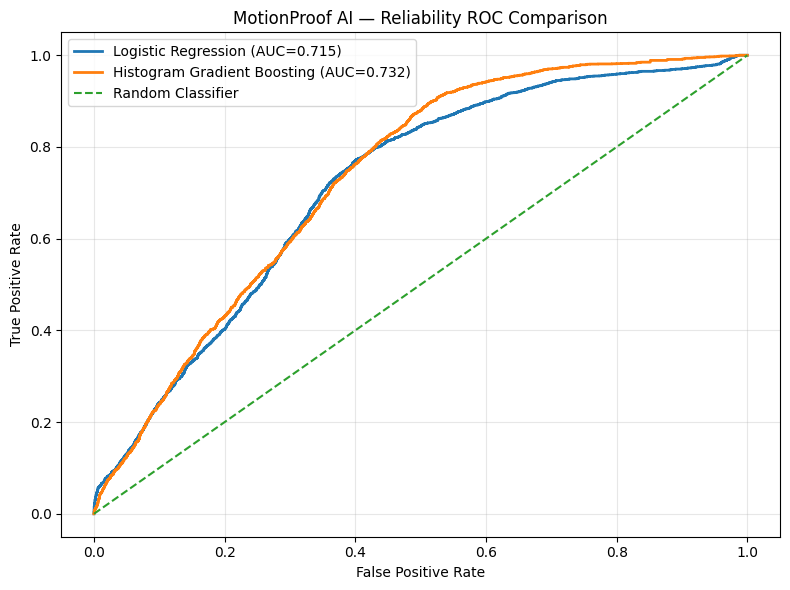

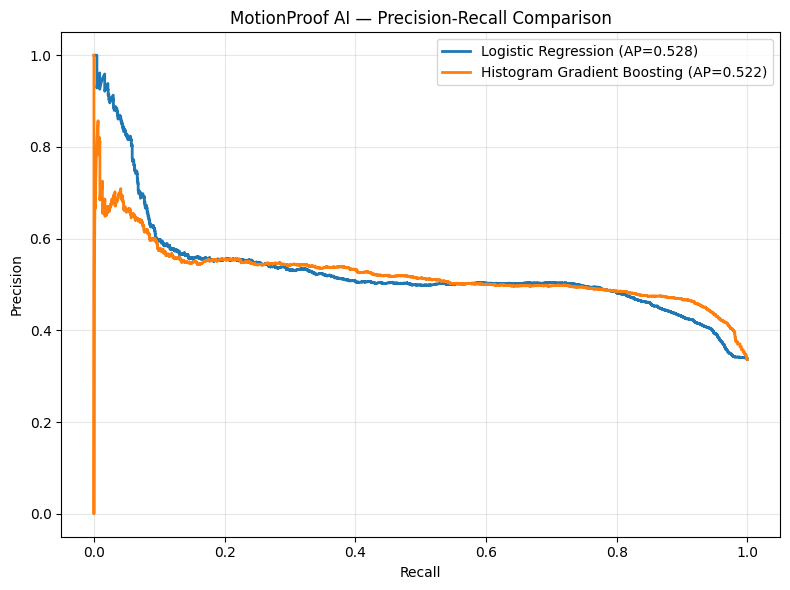


Saved:
validation_classifier_comparison.csv
validation_classifier_per_subject.csv

PASS: Step 33.5 completed.


In [20]:
# ============================================================
# STEP 50.13G.33.5
# MOTIONPROOF AI — RELIABILITY CLASSIFIER COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

print("=" * 75)
print("MOTIONPROOF AI — STEP 33.5")
print("LOGISTIC REGRESSION VS HISTOGRAM GRADIENT BOOSTING")
print("=" * 75)

# ------------------------------------------------------------
# 1. Load validation predictions
# ------------------------------------------------------------

path = (
    ROOT
    / "results/metrics/validation_nonlinear_probabilities.csv"
)

df = pd.read_csv(path)

assert len(df) == 8475
assert set(df["subject"].unique()) == {11, 12}
assert not df[["subject", "window_index"]].duplicated().any()

print("\nValidation windows:", len(df))

# ------------------------------------------------------------
# 2. Prepare ground truth and probabilities
# ------------------------------------------------------------

y_true = df["unreliable_target"].to_numpy()

models = {
    "Logistic Regression": df[
        "unreliable_probability"
    ].to_numpy(),

    "Histogram Gradient Boosting": df[
        "nonlinear_probability"
    ].to_numpy(),
}

for name, probabilities in models.items():
    assert np.isfinite(probabilities).all(), name
    assert ((probabilities >= 0) & (probabilities <= 1)).all(), name

# ------------------------------------------------------------
# 3. Calculate evaluation metrics
# ------------------------------------------------------------

results = []

for name, probabilities in models.items():

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1],
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_true, probabilities
        ),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
    })

comparison = pd.DataFrame(results)

print("\nOVERALL CLASSIFIER COMPARISON")
print("-" * 75)

display(
    comparison.round(4)
)

# ------------------------------------------------------------
# 4. Compare performance by participant
# ------------------------------------------------------------

subject_results = []

for subject in [11, 12]:

    subset = df[df["subject"] == subject]

    subject_y = subset[
        "unreliable_target"
    ].to_numpy()

    for name, column in [
        ("Logistic Regression", "unreliable_probability"),
        ("Histogram Gradient Boosting", "nonlinear_probability"),
    ]:

        probabilities = subset[column].to_numpy()
        predictions = (probabilities >= 0.5).astype(int)

        subject_results.append({
            "Subject": subject,
            "Model": name,
            "Accuracy": accuracy_score(
                subject_y, predictions
            ),
            "Precision": precision_score(
                subject_y, predictions, zero_division=0
            ),
            "Recall": recall_score(
                subject_y, predictions, zero_division=0
            ),
            "F1": f1_score(
                subject_y, predictions, zero_division=0
            ),
        })

subject_comparison = pd.DataFrame(
    subject_results
)

print("\nPER-SUBJECT PERFORMANCE")
print("-" * 75)

display(
    subject_comparison.round(4)
)

# ------------------------------------------------------------
# 5. ROC curve
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

for name, probabilities in models.items():

    fpr, tpr, _ = roc_curve(
        y_true, probabilities
    )

    auc = roc_auc_score(
        y_true, probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={auc:.3f})",
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("MotionProof AI — Reliability ROC Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Precision-recall curve
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

for name, probabilities in models.items():

    precision, recall, _ = precision_recall_curve(
        y_true, probabilities
    )

    ap = average_precision_score(
        y_true, probabilities
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP={ap:.3f})",
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("MotionProof AI — Precision-Recall Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save comparison tables
# ------------------------------------------------------------

output_dir = ROOT / "results/metrics"
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "validation_classifier_comparison.csv",
    index=False,
)

subject_comparison.to_csv(
    output_dir / "validation_classifier_per_subject.csv",
    index=False,
)

print("\nSaved:")
print("validation_classifier_comparison.csv")
print("validation_classifier_per_subject.csv")

print("\nPASS: Step 33.5 completed.")

MOTIONPROOF AI — STEP 33.7

PROBABILITY DISTRIBUTIONS

Logistic Regression
Mean: 0.4625
Standard deviation: 0.2871
Median: 0.4464

Gradient Boosting
Mean: 0.4345
Standard deviation: 0.304
Median: 0.4651

MODEL DISAGREEMENT
Mean absolute probability difference: 0.102
Maximum absolute probability difference: 0.7193
Different classification decisions: 844
Decision disagreement rate: 0.0996

CORRECTNESS ON DISAGREEMENT WINDOWS
Logistic accuracy: 0.5213
Nonlinear accuracy: 0.4787


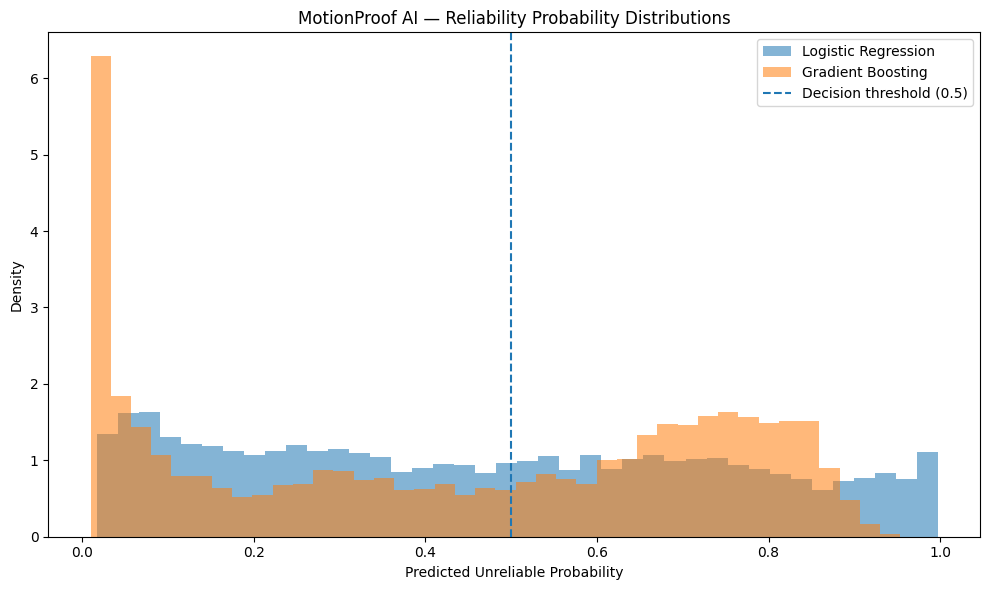


PASS: Step 33.7 completed.


In [21]:
# ============================================================
# STEP 50.13G.33.7
# RELIABILITY PROBABILITY DISTRIBUTION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    ROOT / "results/metrics/validation_nonlinear_probabilities.csv"
)

logistic = df["unreliable_probability"].to_numpy()
nonlinear = df["nonlinear_probability"].to_numpy()
y_true = df["unreliable_target"].to_numpy()

print("=" * 70)
print("MOTIONPROOF AI — STEP 33.7")
print("=" * 70)

print("\nPROBABILITY DISTRIBUTIONS")

for name, probabilities in [
    ("Logistic Regression", logistic),
    ("Gradient Boosting", nonlinear),
]:
    print(f"\n{name}")
    print("Mean:", round(float(probabilities.mean()), 4))
    print("Standard deviation:", round(float(probabilities.std()), 4))
    print("Median:", round(float(np.median(probabilities)), 4))

difference = nonlinear - logistic

print("\nMODEL DISAGREEMENT")
print("Mean absolute probability difference:",
      round(float(np.mean(np.abs(difference))), 4))

print("Maximum absolute probability difference:",
      round(float(np.max(np.abs(difference))), 4))

logistic_labels = logistic >= 0.5
nonlinear_labels = nonlinear >= 0.5

disagreement = logistic_labels != nonlinear_labels

print("Different classification decisions:",
      int(disagreement.sum()))

print("Decision disagreement rate:",
      round(float(disagreement.mean()), 4))

print("\nCORRECTNESS ON DISAGREEMENT WINDOWS")

if disagreement.any():
    logistic_correct = np.mean(
        logistic_labels[disagreement] == y_true[disagreement]
    )
    nonlinear_correct = np.mean(
        nonlinear_labels[disagreement] == y_true[disagreement]
    )

    print("Logistic accuracy:",
          round(float(logistic_correct), 4))
    print("Nonlinear accuracy:",
          round(float(nonlinear_correct), 4))

plt.figure(figsize=(10, 6))

plt.hist(
    logistic,
    bins=40,
    alpha=0.55,
    density=True,
    label="Logistic Regression",
)

plt.hist(
    nonlinear,
    bins=40,
    alpha=0.55,
    density=True,
    label="Gradient Boosting",
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Decision threshold (0.5)",
)

plt.xlabel("Predicted Unreliable Probability")
plt.ylabel("Density")
plt.title("MotionProof AI — Reliability Probability Distributions")
plt.legend()
plt.tight_layout()
plt.show()

print("\nPASS: Step 33.7 completed.")

Project directory: /blue/eee6778/nvasanthakumar/MotionProof-AI
MOTIONPROOF AI — STEP 33.9B
ORIGINAL VS NONLINEAR POLICY COMPARISON

FULL POLICY COMPARISON


,Configuration,policy,accuracy,precision,recall,f1,specificity,false_positive_rate,average_investigations,average_reward
0,Original Logistic,Fixed Rule,0.6808,0.5171,0.7777,0.6212,0.6317,0.3683,1.2833,-0.1211
1,Original Logistic,Learned Fitted Q,0.6793,0.5138,0.8752,0.6475,0.5799,0.4201,0.9447,-0.0075
2,Original Logistic,No Investigation,0.6663,0.5031,0.6750,0.5765,0.6619,0.3381,0.0000,-0.1009
3,Matched Nonlinear,Fixed Rule,0.6805,0.5164,0.7966,0.6266,0.6216,0.3784,1.2224,-0.0996
4,Matched Nonlinear,Learned Fitted Q,0.6868,0.5211,0.8569,0.6481,0.6006,0.3994,0.8604,-0.0031
5,Matched Nonlinear,No Investigation,0.6621,0.4985,0.7104,0.5859,0.6376,0.3624,0.0000,-0.0775



LEARNED AGENT PERFORMANCE CHANGES


,Metric,Original,Nonlinear,Change
0,accuracy,0.6793,0.6868,0.0076
1,precision,0.5138,0.5211,0.0073
2,recall,0.8752,0.8569,-0.0182
3,f1,0.6475,0.6481,0.0006
4,specificity,0.5799,0.6006,0.0206
5,false_positive_rate,0.4201,0.3994,-0.0206
6,average_investigations,0.9447,0.8604,-0.0842
7,average_reward,-0.0075,-0.0031,0.0044


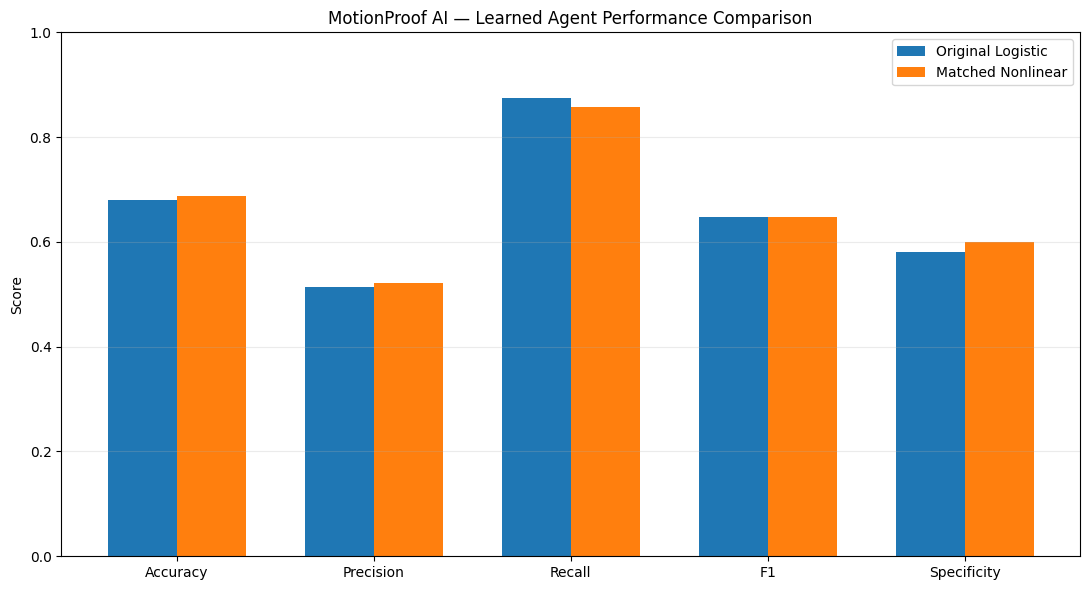


Saved comparison: /blue/eee6778/nvasanthakumar/MotionProof-AI/results/metrics/nonlinear_validation/original_vs_nonlinear_comparison.csv

PASS: Step 33.9B completed.


In [2]:
# ============================================================
# MOTIONPROOF AI — STEP 33.9B
# ORIGINAL VS NONLINEAR AGENT PERFORMANCE
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Locate project automatically
# ------------------------------------------------------------

current = Path.cwd().resolve()

candidates = [
    current,
    current.parent,
    current / "MotionProof-AI",
]

ROOT = next(
    (
        path
        for path in candidates
        if (
            path / "results/metrics/validation_policy_comparison.csv"
        ).exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        f"Could not locate MotionProof-AI from {current}"
    )

print("Project directory:", ROOT)

print("=" * 75)
print("MOTIONPROOF AI — STEP 33.9B")
print("ORIGINAL VS NONLINEAR POLICY COMPARISON")
print("=" * 75)

# ------------------------------------------------------------
# 2. Load results
# ------------------------------------------------------------

original_path = (
    ROOT / "results/metrics/validation_policy_comparison.csv"
)

nonlinear_path = (
    ROOT
    / "results/metrics/nonlinear_validation"
    / "validation_policy_comparison.csv"
)

original = pd.read_csv(original_path)
nonlinear = pd.read_csv(nonlinear_path)

assert set(original["policy"]) == set(nonlinear["policy"])

# ------------------------------------------------------------
# 3. Combine results
# ------------------------------------------------------------

original = original.copy()
nonlinear = nonlinear.copy()

original["Configuration"] = "Original Logistic"
nonlinear["Configuration"] = "Matched Nonlinear"

combined = pd.concat(
    [original, nonlinear],
    ignore_index=True,
)

columns = [
    "Configuration",
    "policy",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "false_positive_rate",
    "average_investigations",
    "average_reward",
]

print("\nFULL POLICY COMPARISON")
display(combined[columns].round(4))

# ------------------------------------------------------------
# 4. Compare learned agent
# ------------------------------------------------------------

original_learned = original.loc[
    original["policy"] == "Learned Fitted Q"
].iloc[0]

nonlinear_learned = nonlinear.loc[
    nonlinear["policy"] == "Learned Fitted Q"
].iloc[0]

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "false_positive_rate",
    "average_investigations",
    "average_reward",
]

changes = []

for metric in metrics:

    old = float(original_learned[metric])
    new = float(nonlinear_learned[metric])

    changes.append({
        "Metric": metric,
        "Original": old,
        "Nonlinear": new,
        "Change": new - old,
    })

changes_df = pd.DataFrame(changes)

print("\nLEARNED AGENT PERFORMANCE CHANGES")
display(changes_df.round(4))

# ------------------------------------------------------------
# 5. Visualization
# ------------------------------------------------------------

plot_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
]

x = np.arange(len(plot_metrics))
width = 0.35

original_values = [
    float(original_learned[m])
    for m in plot_metrics
]

nonlinear_values = [
    float(nonlinear_learned[m])
    for m in plot_metrics
]

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    original_values,
    width,
    label="Original Logistic",
)

plt.bar(
    x + width / 2,
    nonlinear_values,
    width,
    label="Matched Nonlinear",
)

plt.xticks(
    x,
    [m.replace("_", " ").title() for m in plot_metrics],
)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.title(
    "MotionProof AI — Learned Agent Performance Comparison"
)

plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Save comparison
# ------------------------------------------------------------

output_path = (
    ROOT
    / "results/metrics/nonlinear_validation"
    / "original_vs_nonlinear_comparison.csv"
)

combined.to_csv(
    output_path,
    index=False,
)

print("\nSaved comparison:", output_path)
print("\nPASS: Step 33.9B completed.")

MOTIONPROOF AI — STEP 34.2
LEARNED AGENT ERROR VISUALIZATION


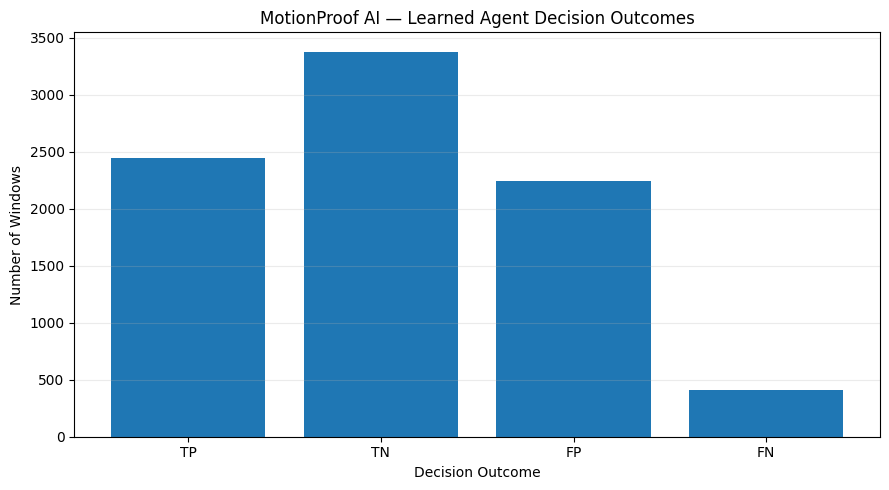

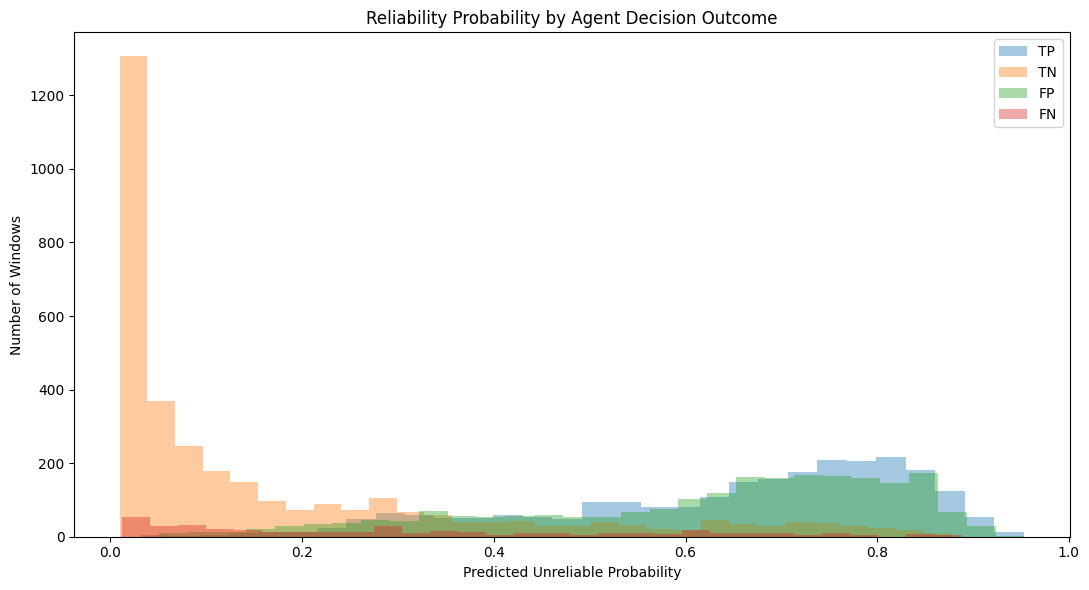

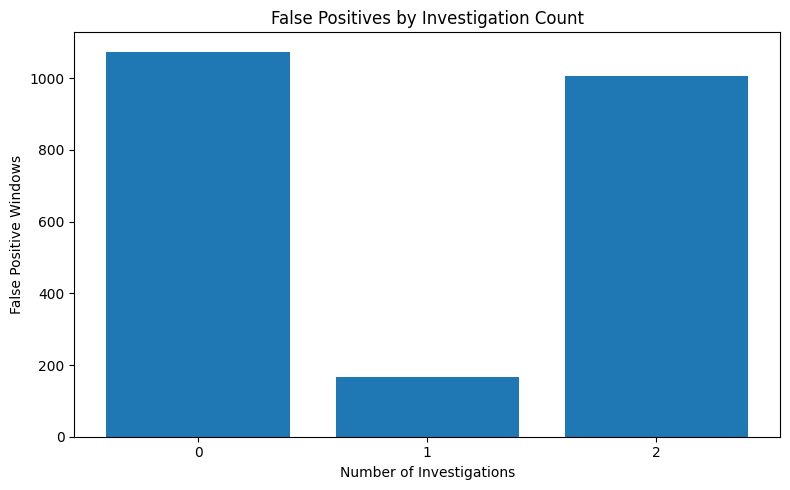


PASS: Step 34.2 completed.


In [3]:
# ============================================================
# MOTIONPROOF AI — STEP 34.2
# AGENT ERROR DISTRIBUTION VISUALIZATION
# ============================================================

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    "/blue/eee6778/nvasanthakumar/MotionProof-AI"
)

path = (
    ROOT
    / "results/metrics/nonlinear_validation"
    / "learned_agent_error_details.csv"
)

df = pd.read_csv(path)

print("=" * 75)
print("MOTIONPROOF AI — STEP 34.2")
print("LEARNED AGENT ERROR VISUALIZATION")
print("=" * 75)

# ------------------------------------------------------------
# Error counts
# ------------------------------------------------------------

counts = (
    df["error_type"]
    .value_counts()
    .reindex(["TP", "TN", "FP", "FN"], fill_value=0)
)

plt.figure(figsize=(9, 5))

plt.bar(
    counts.index,
    counts.values,
)

plt.title("MotionProof AI — Learned Agent Decision Outcomes")
plt.xlabel("Decision Outcome")
plt.ylabel("Number of Windows")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Probability distributions by error type
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

for error_type in ["TP", "TN", "FP", "FN"]:

    subset = df.loc[
        df["error_type"] == error_type,
        "unreliable_probability",
    ]

    plt.hist(
        subset,
        bins=30,
        alpha=0.4,
        label=error_type,
    )

plt.xlabel("Predicted Unreliable Probability")
plt.ylabel("Number of Windows")
plt.title("Reliability Probability by Agent Decision Outcome")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# False positives by investigation count
# ------------------------------------------------------------

fp = df[df["error_type"] == "FP"]

investigation_counts = (
    fp["investigations_used"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    investigation_counts.index.astype(str),
    investigation_counts.values,
)

plt.xlabel("Number of Investigations")
plt.ylabel("False Positive Windows")
plt.title("False Positives by Investigation Count")
plt.tight_layout()
plt.show()

print("\nPASS: Step 34.2 completed.")

In [4]:
# ============================================================
# MOTIONPROOF AI — STEP 35.1
# INVESTIGATION-AWARE ERROR ANALYSIS
# ============================================================

from pathlib import Path

import pandas as pd
import numpy as np

ROOT = Path(
    "/blue/eee6778/nvasanthakumar/MotionProof-AI"
)

df = pd.read_csv(
    ROOT
    / "results/metrics/nonlinear_validation"
    / "learned_agent_error_details.csv"
)

print("=" * 75)
print("MOTIONPROOF AI — STEP 35.1")
print("INVESTIGATION-AWARE ERROR ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. Decision outcomes by investigation count
# ------------------------------------------------------------

table = pd.crosstab(
    df["investigations_used"],
    df["error_type"],
)

table = table.reindex(
    columns=["TP", "TN", "FP", "FN"],
    fill_value=0,
)

print("\nERROR OUTCOMES BY INVESTIGATION COUNT")
display(table)

# ------------------------------------------------------------
# 2. Precision of flagged predictions
# ------------------------------------------------------------

flagged = df[
    df["predicted_unreliable"] == 1
].copy()

precision_by_investigation = (
    flagged.groupby("investigations_used")
    .agg(
        flagged_windows=("predicted_unreliable", "size"),
        true_positives=("unreliable_target", "sum"),
        mean_probability=("unreliable_probability", "mean"),
    )
)

precision_by_investigation["precision"] = (
    precision_by_investigation["true_positives"]
    / precision_by_investigation["flagged_windows"]
)

print("\nFLAG PRECISION BY INVESTIGATION COUNT")
display(precision_by_investigation.round(4))

# ------------------------------------------------------------
# 3. Immediate flags by probability range
# ------------------------------------------------------------

immediate_flags = flagged[
    flagged["investigations_used"] == 0
].copy()

immediate_flags["probability_bin"] = pd.cut(
    immediate_flags["unreliable_probability"],
    bins=np.arange(0, 1.01, 0.1),
    include_lowest=True,
)

immediate_summary = (
    immediate_flags.groupby(
        "probability_bin",
        observed=True,
    )
    .agg(
        flagged_windows=("unreliable_target", "size"),
        true_positives=("unreliable_target", "sum"),
        mean_probability=("unreliable_probability", "mean"),
    )
)

immediate_summary["precision"] = (
    immediate_summary["true_positives"]
    / immediate_summary["flagged_windows"]
)

print("\nIMMEDIATE FLAG PRECISION BY PROBABILITY")
display(immediate_summary.round(4))

print("\nPASS: Step 35.1 completed.")

MOTIONPROOF AI — STEP 35.1
INVESTIGATION-AWARE ERROR ANALYSIS

ERROR OUTCOMES BY INVESTIGATION COUNT


error_type,TP,TN,FP,FN
investigations_used,,,,
0,1374,1446,1074,124
1,141,1214,167,100
2,929,717,1005,184



FLAG PRECISION BY INVESTIGATION COUNT


,flagged_windows,true_positives,mean_probability,precision
investigations_used,,,,
0,2448,1374,0.7427,0.5613
1,308,141,0.6404,0.4578
2,1934,929,0.4955,0.4804



IMMEDIATE FLAG PRECISION BY PROBABILITY


,flagged_windows,true_positives,mean_probability,precision
probability_bin,,,,
"(0.5, 0.6]",170,86,0.5694,0.5059
"(0.6, 0.7]",649,314,0.6572,0.4838
"(0.7, 0.8]",875,470,0.7506,0.5371
"(0.8, 0.9]",710,471,0.8418,0.6634
"(0.9, 1.0]",44,33,0.9156,0.7500



PASS: Step 35.1 completed.


In [5]:
# ============================================================
# MOTIONPROOF AI — STEP 35.2
# TARGETED DECISION CALIBRATION
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

ROOT = Path("/blue/eee6778/nvasanthakumar/MotionProof-AI")

INPUT_PATH = (
    ROOT
    / "results/metrics/nonlinear_validation"
    / "learned_agent_error_details.csv"
)

df = pd.read_csv(INPUT_PATH)

assert len(df) == 8475

y_true = df["unreliable_target"].to_numpy(dtype=int)

original_pred = df[
    "predicted_unreliable"
].to_numpy(dtype=int)

probability = df[
    "unreliable_probability"
].to_numpy(dtype=float)

investigations = df[
    "investigations_used"
].to_numpy(dtype=int)

print("=" * 75)
print("MOTIONPROOF AI — STEP 35.2")
print("TARGETED DECISION CALIBRATION")
print("=" * 75)


# ------------------------------------------------------------
# 1. Evaluation function
# ------------------------------------------------------------

def evaluate_predictions(name, predictions):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1],
    ).ravel()

    return {
        "Configuration": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "False Positive Rate": fp / (fp + tn),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Changed Decisions": int(
            np.sum(predictions != original_pred)
        ),
    }


# ------------------------------------------------------------
# 2. Original policy
# ------------------------------------------------------------

results = []

results.append(
    evaluate_predictions(
        "Original Learned Policy",
        original_pred,
    )
)


# ------------------------------------------------------------
# 3. Candidate calibration rules
# ------------------------------------------------------------

# Only reconsider FLAG_UNRELIABLE decisions.
# ACCEPT decisions remain unchanged.

candidate_rules = [
    ("All Flags >= 0.40", None, 0.40),
    ("All Flags >= 0.50", None, 0.50),
    ("All Flags >= 0.60", None, 0.60),

    ("Immediate Flags >= 0.60", 0, 0.60),
    ("Immediate Flags >= 0.70", 0, 0.70),
    ("Immediate Flags >= 0.80", 0, 0.80),

    ("Two-Investigation Flags >= 0.40", 2, 0.40),
    ("Two-Investigation Flags >= 0.50", 2, 0.50),
    ("Two-Investigation Flags >= 0.60", 2, 0.60),
]

for name, investigation_filter, threshold in candidate_rules:

    predictions = original_pred.copy()

    mask = original_pred == 1

    if investigation_filter is not None:
        mask &= investigations == investigation_filter

    mask &= probability < threshold

    predictions[mask] = 0

    results.append(
        evaluate_predictions(
            name,
            predictions,
        )
    )


# ------------------------------------------------------------
# 4. Compare results
# ------------------------------------------------------------

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    ["F1", "Accuracy"],
    ascending=False,
)

print("\nCALIBRATION EXPERIMENT RESULTS")
print("-" * 75)

display(
    comparison.round(4)
)


# ------------------------------------------------------------
# 5. Identify candidates preserving recall
# ------------------------------------------------------------

baseline_recall = float(
    comparison.loc[
        comparison["Configuration"] == "Original Learned Policy",
        "Recall",
    ].iloc[0]
)

minimum_recall = baseline_recall - 0.03

eligible = comparison[
    comparison["Recall"] >= minimum_recall
].copy()

print("\nCANDIDATES WITH RECALL LOSS <= 3 PERCENTAGE POINTS")
print("-" * 75)

display(
    eligible.sort_values(
        ["F1", "Accuracy"],
        ascending=False,
    ).round(4)
)


# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

OUTPUT_PATH = (
    ROOT
    / "results/metrics/nonlinear_validation"
    / "targeted_calibration_experiment.csv"
)

if OUTPUT_PATH.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing results: {OUTPUT_PATH}"
    )

comparison.to_csv(
    OUTPUT_PATH,
    index=False,
)

print("\nSaved:", OUTPUT_PATH)
print("\nPASS: Step 35.2 completed.")

MOTIONPROOF AI — STEP 35.2
TARGETED DECISION CALIBRATION

CALIBRATION EXPERIMENT RESULTS
---------------------------------------------------------------------------


,Configuration,Accuracy,Precision,Recall,F1,False Positive Rate,TP,TN,FP,FN,Changed Decisions
0,Original Learned Policy,0.6868,0.5211,0.8569,0.6481,0.3994,2444,3377,2246,408,0
4,Immediate Flags >= 0.60,0.6866,0.5217,0.8268,0.6397,0.3845,2358,3461,2162,494,170
7,Two-Investigation Flags >= 0.40,0.6940,0.5326,0.7416,0.6200,0.3301,2115,3767,1856,737,719
1,All Flags >= 0.40,0.6938,0.5325,0.7374,0.6184,0.3283,2103,3777,1846,749,741
5,Immediate Flags >= 0.70,0.6891,0.5280,0.7167,0.6081,0.3249,2044,3796,1827,808,819
8,Two-Investigation Flags >= 0.50,0.6936,0.5350,0.6827,0.5999,0.3009,1947,3931,1692,905,1051
2,All Flags >= 0.50,0.6946,0.5369,0.6729,0.5973,0.2943,1919,3968,1655,933,1116
9,Two-Investigation Flags >= 0.60,0.6885,0.5315,0.6276,0.5756,0.2806,1790,4045,1578,1062,1322
3,All Flags >= 0.60,0.6885,0.5345,0.5757,0.5544,0.2543,1642,4193,1430,1210,1618
6,Immediate Flags >= 0.80,0.6814,0.5254,0.5519,0.5383,0.2529,1574,4201,1422,1278,1694



CANDIDATES WITH RECALL LOSS <= 3 PERCENTAGE POINTS
---------------------------------------------------------------------------


,Configuration,Accuracy,Precision,Recall,F1,False Positive Rate,TP,TN,FP,FN,Changed Decisions
0,Original Learned Policy,0.6868,0.5211,0.8569,0.6481,0.3994,2444,3377,2246,408,0



Saved: /blue/eee6778/nvasanthakumar/MotionProof-AI/results/metrics/nonlinear_validation/targeted_calibration_experiment.csv

PASS: Step 35.2 completed.
